# Previsão de Atrasos em Entregas 🚚

## Descrição do Problema

A EntregaCerta é uma empresa fictícia de comércio eletrônico que atende clientes em diferentes regiões do Brasil. A empresa trabalha com múltiplas transportadoras e modalidades de envio.

Recentemente, a equipe de operações identificou dificuldades em cumprir os prazos de entrega prometidos aos clientes. Como os atrasos podem comprometer a satisfação dos consumidores e gerar custos operacionais, a empresa busca compreender quais fatores estão associados a esse problema e identificar antecipadamente os pedidos com maior risco de atraso.

Para isso, pretende utilizar técnicas de Ciência de Dados e Machine Learning, além de ferramentas de visualização, como o Power BI, para apoiar a tomada de decisões e melhorar o planejamento logístico.

## Base de Dados

A base de dados é uma base sintética, gerada pelo ChatGPT, composta por aproximadamente 30 mil registros de pedidos de uma empresa fictícia de comércio eletrônico. Ela possui informações relacionadas às entregas de produtos para diferentes regiões do Brasil, incluindo características dos pedidos, categorias de produtos, transportadoras, modalidades de envio, distâncias percorridas, prazos prometidos, disponibilidade de estoque e condições operacionais, como congestionamento das rotas e previsão de chuva. Além da variável alvo 'atrasou', que registra 0 para não e 1 para sim.

## Importações

In [1]:
import pandas as pd
import plotly.express as px
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import make_column_transformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split

## 1. Carregamento e Exploração de Dados

### 1.1 Carregamento da Base de Dados

In [2]:
df = pd.read_csv('../data/raw/delivery_orders.csv')
df.head()

,pedido_id,data_pedido,regiao_destino,estado_destino,categoria_produto,transportadora,modalidade_envio,distancia_km,valor_pedido_brl,estoque_disponivel,carga_centro_distribuicao_pct,chuva_prevista_mm,congestionamento_rota,lead_time_fornecedor_dias,dias_prometidos,fim_de_semana,atrasou,dias_atraso,data_entrega
0,PED000001,2024-04-09,Nordeste,PB,Eletrônicos,ViaExpress,Padrão,956,55.88,Sim,59,6.9,Alto,1.5,5,0,0,0,2024-04-14
1,PED000002,2024-04-14,Sudeste,SP,Beleza,ViaExpress,Econômica,402,36.89,Sim,76,0.5,Baixo,4.4,6,1,0,0,2024-04-20
2,PED000003,2024-11-06,Nordeste,MA,Beleza,BrasilLog,Econômica,541,169.20,Não,78,4.9,Moderado,3.9,7,0,1,5,2024-11-18
3,PED000004,2024-01-02,Sudeste,RJ,Eletrônicos,BrasilLog,Padrão,3302,103.07,Sim,74,0.4,Baixo,4.7,14,0,1,5,2024-01-21
4,PED000005,2025-05-20,Sudeste,MG,Casa e decoração,RotaSul,Expressa,1447,62.23,Sim,69,9.0,Baixo,3.2,5,0,0,0,2025-05-25


### 1.2 Visão Geral dos Dados

In [3]:
df.shape

(30000, 19)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 19 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   pedido_id                      30000 non-null  object 
 1   data_pedido                    30000 non-null  object 
 2   regiao_destino                 30000 non-null  object 
 3   estado_destino                 30000 non-null  object 
 4   categoria_produto              30000 non-null  object 
 5   transportadora                 30000 non-null  object 
 6   modalidade_envio               30000 non-null  object 
 7   distancia_km                   30000 non-null  int64  
 8   valor_pedido_brl               30000 non-null  float64
 9   estoque_disponivel             30000 non-null  object 
 10  carga_centro_distribuicao_pct  30000 non-null  int64  
 11  chuva_prevista_mm              30000 non-null  float64
 12  congestionamento_rota          30000 non-null 

In [5]:
df.describe()

,distancia_km,valor_pedido_brl,carga_centro_distribuicao_pct,chuva_prevista_mm,lead_time_fornecedor_dias,dias_prometidos,fim_de_semana,atrasou,dias_atraso
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000
mean,880.945333,87.535554,67.728900,9.620873,3.256920,5.912267,0.283900,0.448433,1.792833
std,603.260141,88.509881,16.532122,8.759490,1.891821,2.786161,0.450896,0.497342,2.393750
min,15.000000,25.000000,15.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000
25%,434.000000,33.510000,57.000000,3.300000,1.900000,4.000000,0.000000,0.000000,0.000000
50%,746.000000,59.945000,68.000000,7.200000,3.200000,6.000000,0.000000,0.000000,0.000000
75%,1181.000000,106.235000,79.000000,13.325000,4.500000,7.000000,1.000000,1.000000,4.000000
max,3500.000000,1570.700000,100.000000,90.000000,10.900000,20.000000,1.000000,1.000000,7.000000


In [6]:
df.isnull().sum()

pedido_id                        0
data_pedido                      0
regiao_destino                   0
estado_destino                   0
categoria_produto                0
transportadora                   0
modalidade_envio                 0
distancia_km                     0
valor_pedido_brl                 0
estoque_disponivel               0
carga_centro_distribuicao_pct    0
chuva_prevista_mm                0
congestionamento_rota            0
lead_time_fornecedor_dias        0
dias_prometidos                  0
fim_de_semana                    0
atrasou                          0
dias_atraso                      0
data_entrega                     0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.select_dtypes(include="object").nunique()

pedido_id                30000
data_pedido                730
regiao_destino               5
estado_destino              27
categoria_produto            6
transportadora               4
modalidade_envio             3
estoque_disponivel           2
congestionamento_rota        3
data_entrega               746
dtype: int64

De acordo com a visão geral dos dados, destaca-se que:
1. possui 30.000 registros e 19 colunas
2. os tipos de dados de cada coluna varia entre object, int e float
3. existem atrasos máximo de 7 dias e mínimos de 0 dias, com desvio padrão de aproximadamente 2 dias de atraso
4. não foram identificados valores nulos e nem duplicados. Destaca-se que a base sintética foi sem esses ocorrências, a fim de focar nas etapas de análise e modelagem preditiva.

### 1.3 Análise Exploratória

#### 1.3.1 Distribuição das Distâncias de Entrega

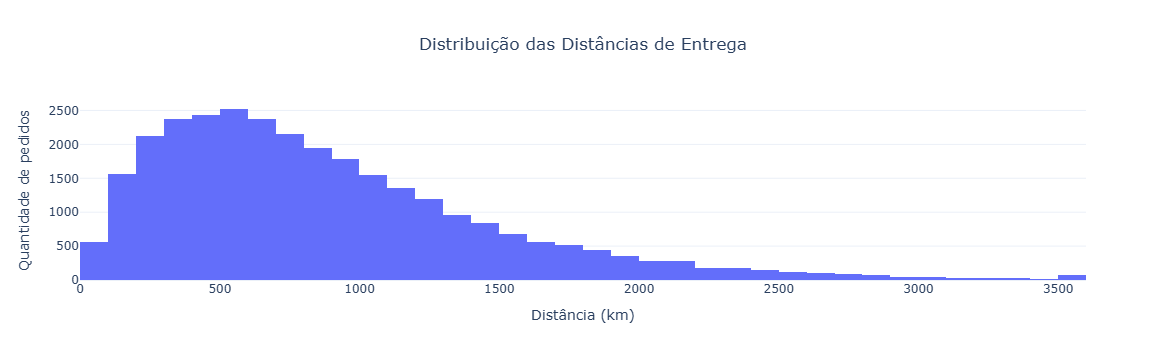

In [9]:
fig = px.histogram(
    df,
    x="distancia_km",
    nbins=40,
    title="Distribuição das Distâncias de Entrega",
    labels={
        "distancia_km": "Distância (km)",
        "count": "Quantidade de pedidos"
    },
    template="plotly_white"
)

fig.update_layout(
    title_x=0.5,
    xaxis_title="Distância (km)",
    yaxis_title="Quantidade de pedidos"
)

fig.show()

A visualização da Distribuição de Distâncias nos permite analisar que a quantidade de pedidos está concentrada em distâncias menores, com uma leve cauda indicando que quanto maior a distância, menores são os pedidos. 

In [10]:
df["distancia_km"].value_counts().head()

distancia_km
3500    67
539     41
374     40
485     40
378     39
Name: count, dtype: int64

In [11]:
df["distancia_km"].value_counts().sort_index().tail(10)

distancia_km
3455     1
3456     1
3460     1
3462     1
3470     1
3480     1
3481     1
3489     1
3497     1
3500    67
Name: count, dtype: int64

Algo que chamou a atenção foi que a distância de 3500 km possui muitos registros a mais que as distâncias próximas a ela, o que pode indicar um limite aplicado na geração da base sintética, em que se considerou 3500 km como limite superior. Porém, como esse valor corresponde a uma parcela muito pequena em comparação com os demais, não há a necessidade de removê-lo.

#### 1.3.2 Distribuição de Valores de Pedido

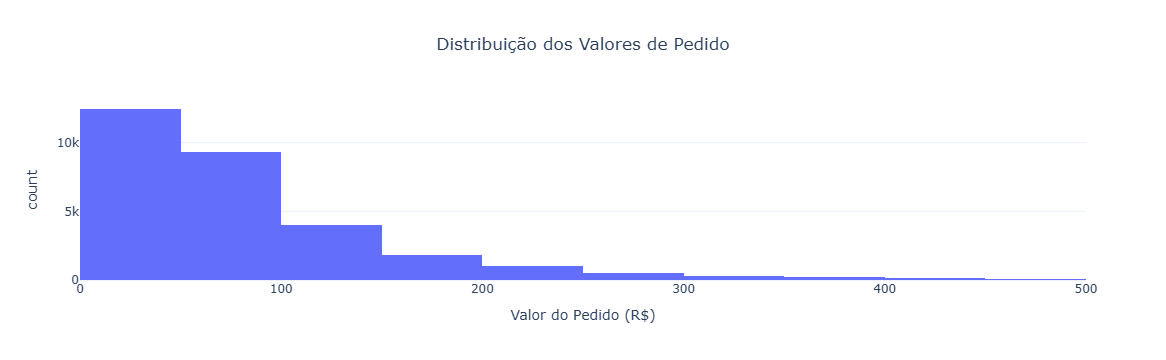

In [12]:
fig = px.histogram(
    df,
    x="valor_pedido_brl",
    nbins=50,
    title="Distribuição dos Valores de Pedido",
    labels={
        "valor_pedido_brl": "Valor do Pedido (R$)",
        "count": "Quantidade de Pedidos"
    },
    template="plotly_white"
)

fig.update_xaxes(range=[0, 500])
fig.update_layout(title_x=0.5)

fig.show()

Neste histograma, nota-se que, assim como as distâncias, os valores baixos são os que mais se concetram nos pedidos, com mais de 12 mil pedidos na faixa de 0 a 50 reais. 
Uma observação importante é que, para visualizar melhor onde há a maior distribuição, a visualização foi diminuída em até 500 reais, mas, ao interagir com o gráfico, é possível analisar que existem valores até perto de R$1.600.

#### 1.3.3 Distribuição de Prazos Prometidos

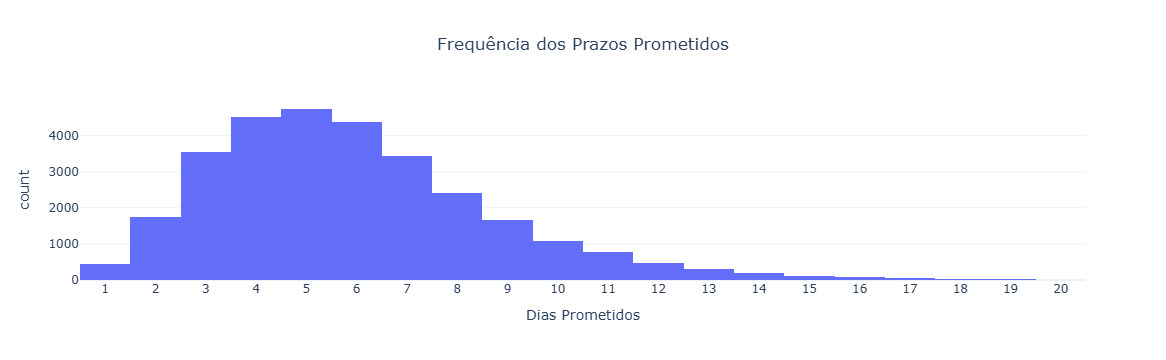

In [13]:
fig = px.histogram(
    df,
    x="dias_prometidos",
    title="Frequência dos Prazos Prometidos",
    labels={
        "dias_prometidos": "Dias Prometidos",
        "count": "Quantidade de Pedidos"
    },
    template="plotly_white"
)

fig.update_layout(title_x=0.5)
fig.update_xaxes(dtick=1)

fig.show()

Segundo o gráfico acima, há uma grande concentração de pedidos entre 3 e 7 dias prometidos pela empresa. A relação entre os dias prometidos e os atrasos, será observada em um momento posterior.

#### 1.3.4 Distribuição de Tempo de Fornecimento dos Produtos

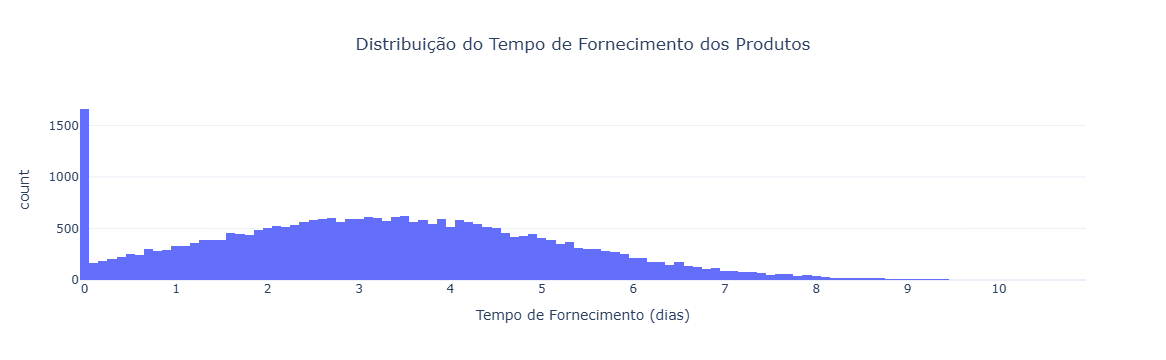

In [14]:
fig = px.histogram(
    df,
    x="lead_time_fornecedor_dias",
    title="Distribuição do Tempo de Fornecimento dos Produtos",
    labels={
        "lead_time_fornecedor_dias": "Tempo de Fornecimento (dias)",
        "count": "Quantidade de Pedidos"
    },
    template="plotly_white"
)

fig.update_layout(title_x=0.5)
fig.update_xaxes(dtick=1)

fig.show()

Com essa visualização, percebe-se que pedidos com tempo de fornecimento de 0 dias se destacam. Isso indica que não houve tempo de espera para o abastecimento dos produtos.

#### 1.3.5 Verificação de Outliers

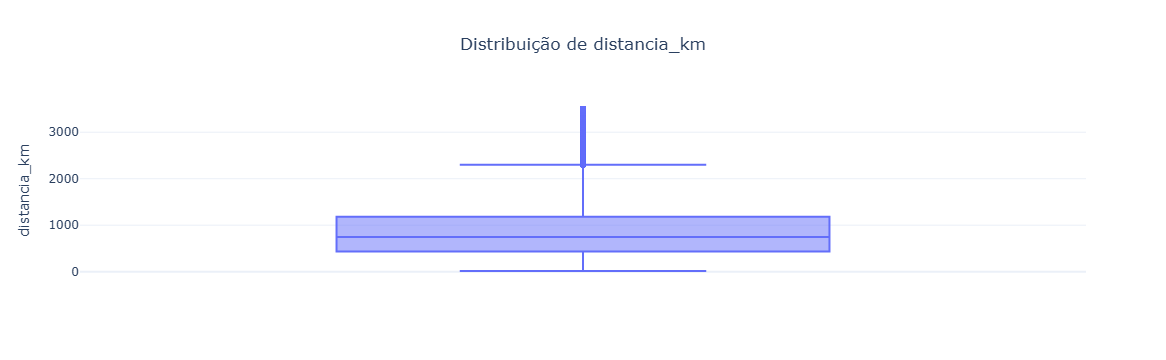

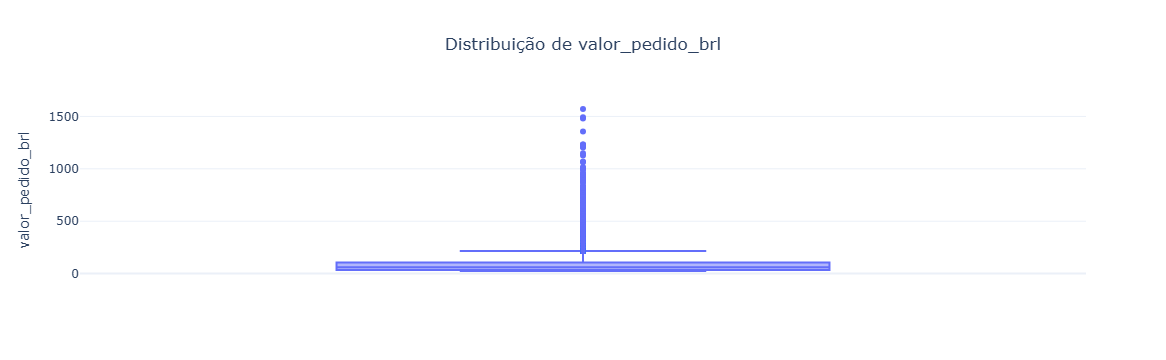

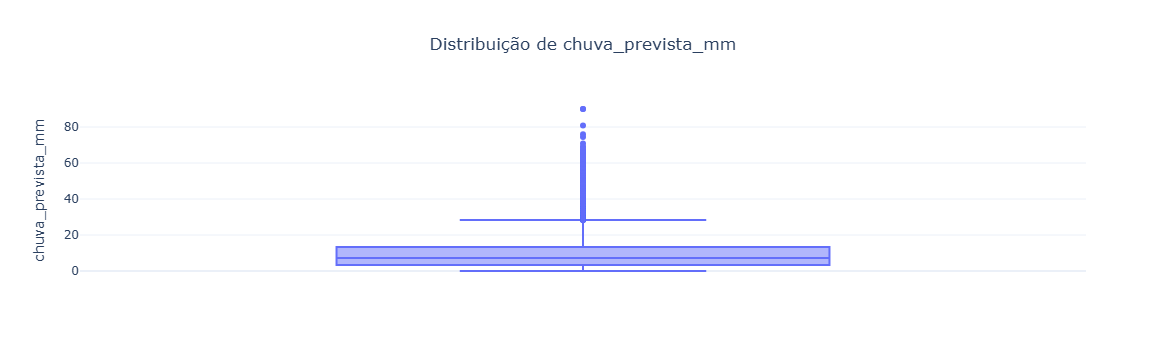

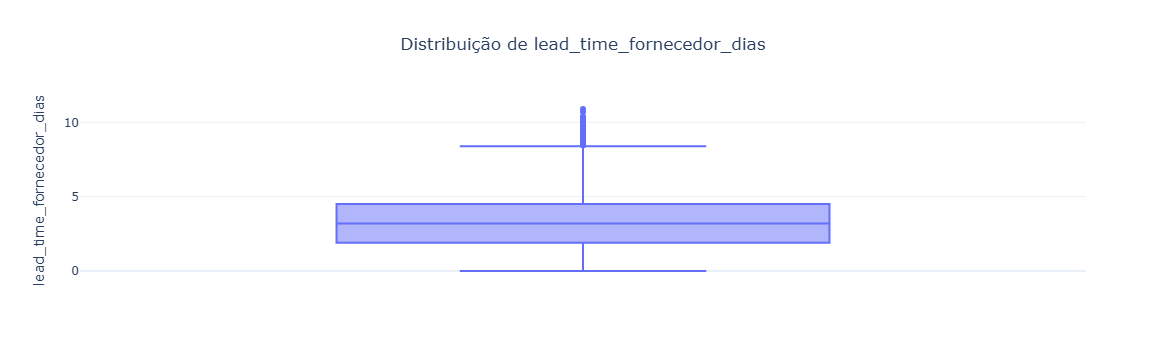

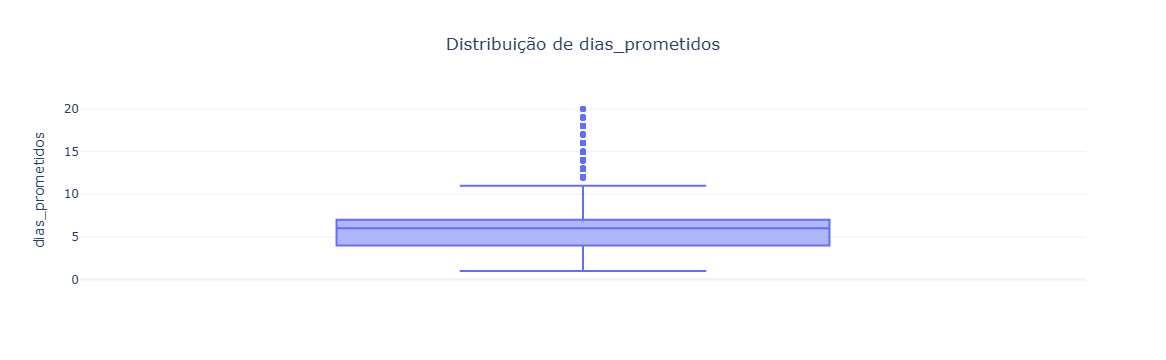

In [15]:
colunas = [
    "distancia_km",
    "valor_pedido_brl",
    "chuva_prevista_mm",
    "lead_time_fornecedor_dias",
    "dias_prometidos"
]

for coluna in colunas:
    fig = px.box(
        df,
        y=coluna,
        title=f"Distribuição de {coluna}",
        template="plotly_white"
    )

    fig.update_layout(title_x=0.5)
    fig.show()

Existe um grande número de possíveis outliers principalmente nas variáveis de distância e valor do pedido, o que condiz com o que foi analisado anteriormente, onde há uma concetração de pedidos com distância e valores menores. Ademais, também nota-se outros possíveis outliers na previsão de chuvas em mm. Porém, essas ocorrências serão mantidas inicialmente, considerando que podem representar características legítimas dos pedidos. 

#### 1.3.6 Análise das Variáveis Categóricas

In [16]:
df["modalidade_envio"].value_counts()

modalidade_envio
Padrão       13123
Econômica    11391
Expressa      5486
Name: count, dtype: int64

In [17]:
df["congestionamento_rota"].value_counts()

congestionamento_rota
Moderado    13793
Baixo       10222
Alto         5985
Name: count, dtype: int64

In [18]:
df["regiao_destino"].value_counts()

regiao_destino
Sudeste         11867
Nordeste         7984
Sul              5095
Centro-Oeste     2636
Norte            2418
Name: count, dtype: int64

Através dessas contagens de algumas variáveis categóricas, nota-se que:
1. as modalidades de envio mais utilizadas são Padrão e Econômica
2. o congestionamento Moderado se destaca, posteriormente será analisado se s condições de congestionamento estão associadas à ocorrência de atrasos
3. a região com mais pedidos é a Sudeste e a com menos é a Norte. Essa diferença pode estar relacionada à distribuição geográfica da demanda, mas não é possível determinar sua causa apenas com os dados disponíveis.

### 1.4 Análise da Variável-Alvo

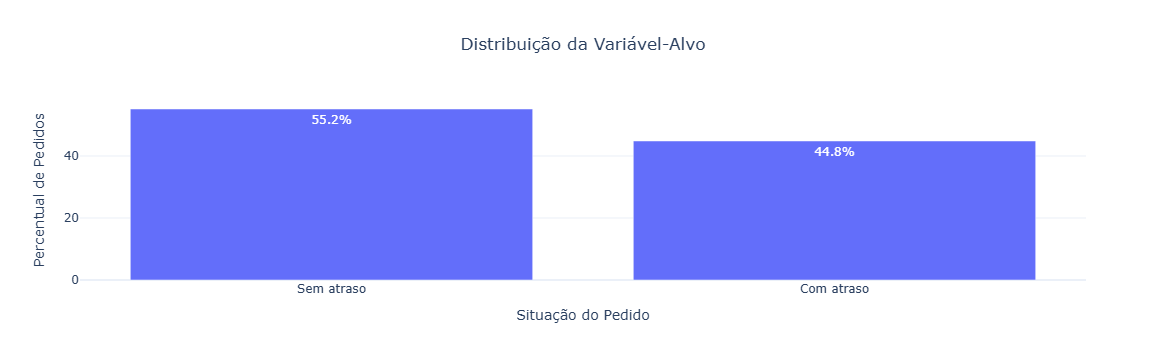

In [19]:
contagem = df["atrasou"].value_counts().sort_index()

percentual = df["atrasou"].value_counts(normalize=True).sort_index() * 100

dados = pd.DataFrame({
    "Situação": ["Sem atraso", "Com atraso"],
    "Quantidade": contagem.values,
    "Percentual": percentual.values
})

fig = px.bar(
    dados,
    x="Situação",
    y="Percentual",
    text=dados["Percentual"].round(1).astype(str) + "%",
    title="Distribuição da Variável-Alvo",
    labels={
        "Situação": "Situação do Pedido",
        "Percentual": "Percentual de Pedidos"
    },
    template="plotly_white"
)

fig.update_layout(title_x=0.5)
fig.show()

Observa-se que a porcentagem de pedidos com atraso totaliza 44.8%, o que indica uma grande proporção. Isso reforça a necessidade de investigar posteriormente sua relação com outras características, para identificar as possíveis causas e realizar as previsões. 

## 2. Preparação dos Dados

### 2.1 Remoção de Variáveis Irrelevantes

In [20]:
df.columns

Index(['pedido_id', 'data_pedido', 'regiao_destino', 'estado_destino',
       'categoria_produto', 'transportadora', 'modalidade_envio',
       'distancia_km', 'valor_pedido_brl', 'estoque_disponivel',
       'carga_centro_distribuicao_pct', 'chuva_prevista_mm',
       'congestionamento_rota', 'lead_time_fornecedor_dias', 'dias_prometidos',
       'fim_de_semana', 'atrasou', 'dias_atraso', 'data_entrega'],
      dtype='object')

In [21]:
df = df.drop(columns=['pedido_id', 'dias_atraso', 'data_entrega'])

In [22]:
df.columns

Index(['data_pedido', 'regiao_destino', 'estado_destino', 'categoria_produto',
       'transportadora', 'modalidade_envio', 'distancia_km',
       'valor_pedido_brl', 'estoque_disponivel',
       'carga_centro_distribuicao_pct', 'chuva_prevista_mm',
       'congestionamento_rota', 'lead_time_fornecedor_dias', 'dias_prometidos',
       'fim_de_semana', 'atrasou'],
      dtype='object')

As variáveis pedido_id, dias_atraso e data_entrega foram removidas. As duas últimas guardam informações posteriores a entrega, portanto não são adequadas para serem preditoras, pois poderiam contribuir para o data leakage.

### 2.2 Tratamento de Variáveis Categóricas

In [23]:
df.select_dtypes(include='object').columns

Index(['data_pedido', 'regiao_destino', 'estado_destino', 'categoria_produto',
       'transportadora', 'modalidade_envio', 'estoque_disponivel',
       'congestionamento_rota'],
      dtype='object')

In [24]:
df.select_dtypes(include='object').nunique()

data_pedido              730
regiao_destino             5
estado_destino            27
categoria_produto          6
transportadora             4
modalidade_envio           3
estoque_disponivel         2
congestionamento_rota      3
dtype: int64

In [25]:
df["estoque_disponivel"].unique()

array(['Sim', 'Não'], dtype=object)

Como a variável estoque_disponível possui apenas 2 valores, será aplicada uma codificação binária, ao invés de utilizar OneHotEnconding como nas demais.

In [26]:
df['estoque_disponivel'] = df['estoque_disponivel'].map({
    'Sim': 1,
    'Não': 0
})
df['estoque_disponivel']

0        1
1        1
2        0
3        1
4        1
        ..
29995    1
29996    1
29997    0
29998    1
29999    1
Name: estoque_disponivel, Length: 30000, dtype: int64

In [27]:
df['data_pedido'].head()

0    2024-04-09
1    2024-04-14
2    2024-11-06
3    2024-01-02
4    2025-05-20
Name: data_pedido, dtype: object

A variável data_pedido precisa ser convertida para date_time. Porém, como o enconder não lida com datas, serão extraídas informações de mês do pedido e dia da semana, pois assim é possível tratá-las no OneHot sem perder informações que possam ser relevantes.

In [28]:
df['data_pedido'] = pd.to_datetime(df['data_pedido'])

df['mes_pedido'] = df['data_pedido'].dt.month
df['dia_semana_pedido'] = df['data_pedido'].dt.dayofweek

df = df.drop(columns=['data_pedido'])
df.head()

,regiao_destino,estado_destino,categoria_produto,transportadora,modalidade_envio,distancia_km,valor_pedido_brl,estoque_disponivel,carga_centro_distribuicao_pct,chuva_prevista_mm,congestionamento_rota,lead_time_fornecedor_dias,dias_prometidos,fim_de_semana,atrasou,mes_pedido,dia_semana_pedido
0,Nordeste,PB,Eletrônicos,ViaExpress,Padrão,956,55.88,1,59,6.9,Alto,1.5,5,0,0,4,1
1,Sudeste,SP,Beleza,ViaExpress,Econômica,402,36.89,1,76,0.5,Baixo,4.4,6,1,0,4,6
2,Nordeste,MA,Beleza,BrasilLog,Econômica,541,169.20,0,78,4.9,Moderado,3.9,7,0,1,11,2
3,Sudeste,RJ,Eletrônicos,BrasilLog,Padrão,3302,103.07,1,74,0.4,Baixo,4.7,14,0,1,1,1
4,Sudeste,MG,Casa e decoração,RotaSul,Expressa,1447,62.23,1,69,9.0,Baixo,3.2,5,0,0,5,1


In [29]:
colunas_categoricas = ['regiao_destino', 'estado_destino', 'categoria_produto',
                       'transportadora', 'modalidade_envio', 'congestionamento_rota', 
                       'mes_pedido', 'dia_semana_pedido']

one_hot = make_column_transformer(
    (OneHotEncoder(
        handle_unknown='ignore'
    ), colunas_categoricas),
    remainder='passthrough',
    sparse_threshold=0
)

Foi aplicado o OneHotEnconder nas variáveis categóricas, e só será executado após dividir os dados de treino e teste e selecionar as variáveis preditoras, para que não haja data leakage.

### 2.3 Normalização das Variáveis Numéricas

In [30]:
colunas_numericas = [
    'distancia_km',
    'valor_pedido_brl',
    'carga_centro_distribuicao_pct',
    'chuva_prevista_mm',
    'lead_time_fornecedor_dias',
    'dias_prometidos'
]

In [31]:
scaler = MinMaxScaler()

Assim como nas variáveis categóricas, as colunas numéricas foram separadas e foi implementado o scaler, que será executado somente após dividir os dados e escolher as variáveis preditoras.

### 2.4 Divisão dos Dados em Treino e Teste

In [32]:
X = df.drop(columns=['atrasou'])
y = df['atrasou']

In [33]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [34]:
print("Treinamento:", X_train.shape)
print("Teste:", X_test.shape)

print("\nDistribuição da variável-alvo:")
print("Treinamento:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTeste:")
print(y_test.value_counts(normalize=True) * 100)

Treinamento: (24000, 16)
Teste: (6000, 16)

Distribuição da variável-alvo:
Treinamento:
atrasou
0    55.158333
1    44.841667
Name: proportion, dtype: float64

Teste:
atrasou
0    55.15
1    44.85
Name: proportion, dtype: float64


Foram separados 80% dos dados para treino e 20% para teste. A variável alvo ficou com uma distribuição de aproximadamente 55% para não e 44% para sim, em ambos treino e teste.

## 3. Análise e Seleção de Variáveis

### 3.1 Análise de Correlação

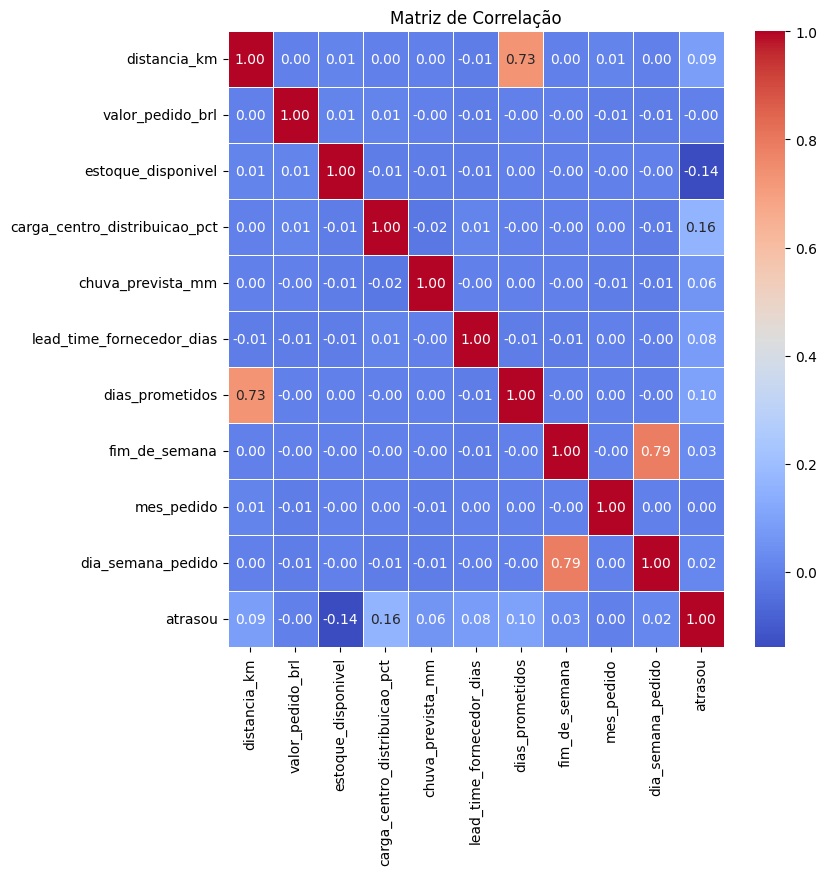

In [35]:
correlation_matrix = pd.concat([X_train, y_train], axis=1).corr(numeric_only=True).round(2)

fig, ax = plt.subplots(figsize=(8, 8))

sns.heatmap(
    data=correlation_matrix,
    annot=True,
    linewidths=.5,
    ax=ax,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Matriz de Correlação')
plt.show()

De acordo com a análise da matrix de correlação, identificou-se que:
* carga_centro_distribuicao_pct apresenta a maior correlação positiva, indicando uma associação positiva fraca com a ocorrência de atrasos.
* estoque_disponivel apresenta correlação negativa, sugerindo que pedidos com estoque disponível tendem a apresentar menor ocorrência de atrasos.
* dias_prometidos, distancia_km, lead_time_fornecedor_dias e chuva_prevista_mm apresentam baixas correlações positivas.

### 3.2 Relação entre as Variáveis e a Variável-Alvo

#### 3.2.1 Variáveis Numéricas

In [36]:
colunas_numericas

['distancia_km',
 'valor_pedido_brl',
 'carga_centro_distribuicao_pct',
 'chuva_prevista_mm',
 'lead_time_fornecedor_dias',
 'dias_prometidos']

In [37]:
df_train = X_train.copy()
df_train['atrasou'] = y_train

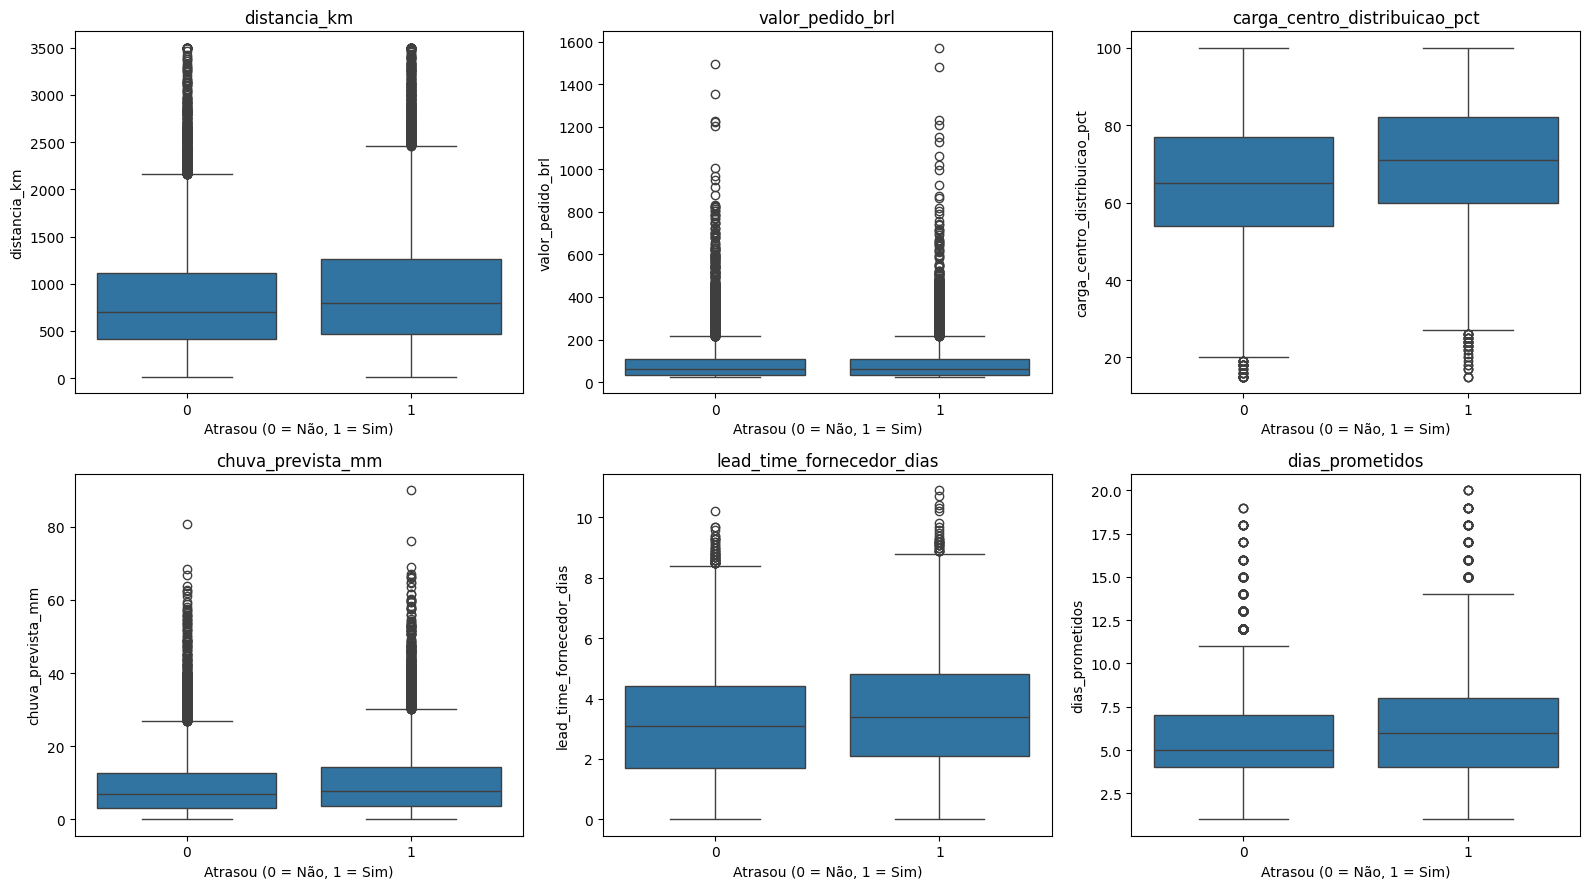

In [38]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for coluna, ax in zip(colunas_numericas, axes.flatten()):
    sns.boxplot(
        data=df_train,
        x='atrasou',
        y=coluna,
        ax=ax
    )
    ax.set_title(coluna)
    ax.set_xlabel('Atrasou (0 = Não, 1 = Sim)')

plt.tight_layout()
plt.show()

Análise de cada boxplot:
- distancia_km: a mediana é um pouco maior nos pedidos atrasados, mas há grande sobreposição entre as distribuições, então distancia possui baixa correlação com 'atrasou'.
- valor_pedido_brl: as medianas próximas indicam que possui baixa correlação com a variável alvo.
- carga_centro_distribuicao_pct: a mediana nos atrasos é a maior de todos os outros boxplots, logo a carga possui mais correlação com o problema do que as demais.
- chuva_prevista_mm: a mediana de 1 está ligeiramente superior, porém as distribuições apresentam sobreposição, logo há uma baixa correlação com o alvo.
- lead_time_fornecedor_dias: assim como a distância e a chuva prevista, a lead_time também apresenta sobreposição, apesar da mediana de 1 estar levemente acima.
- dias_prometidos: a mediana é superior aos pedidos de atraso, indicando também alguma correlação com a variável alvo.

#### 3.2.2 Variáveis Categóricas

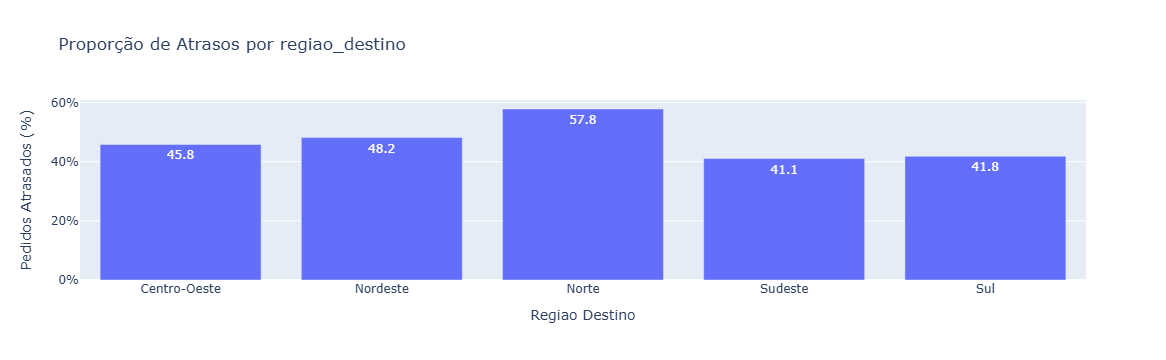

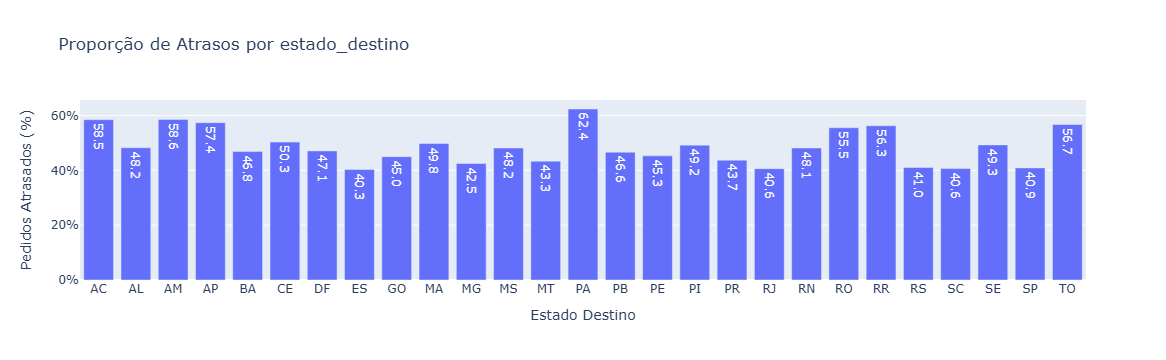

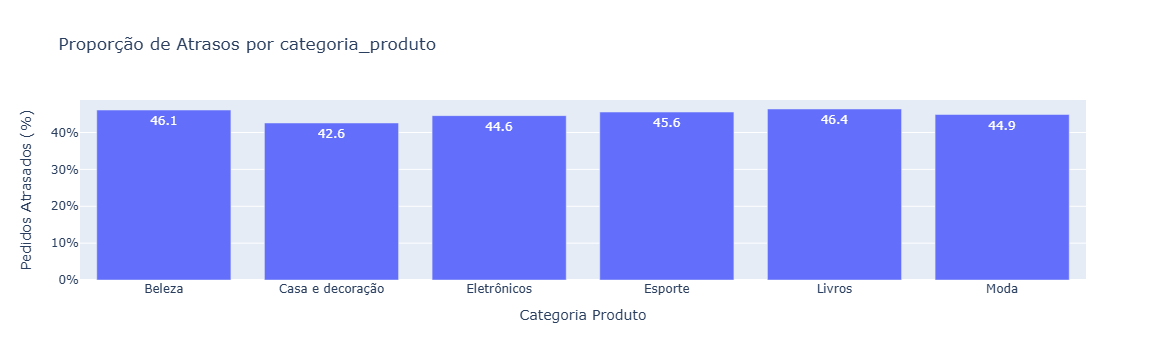

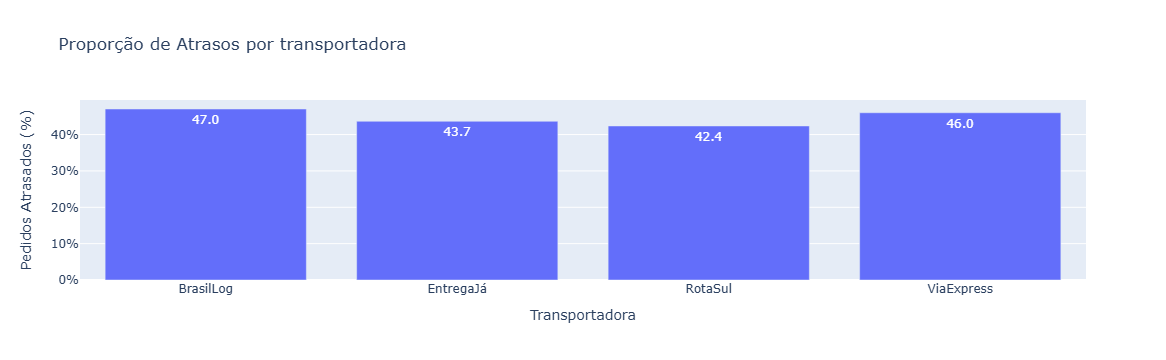

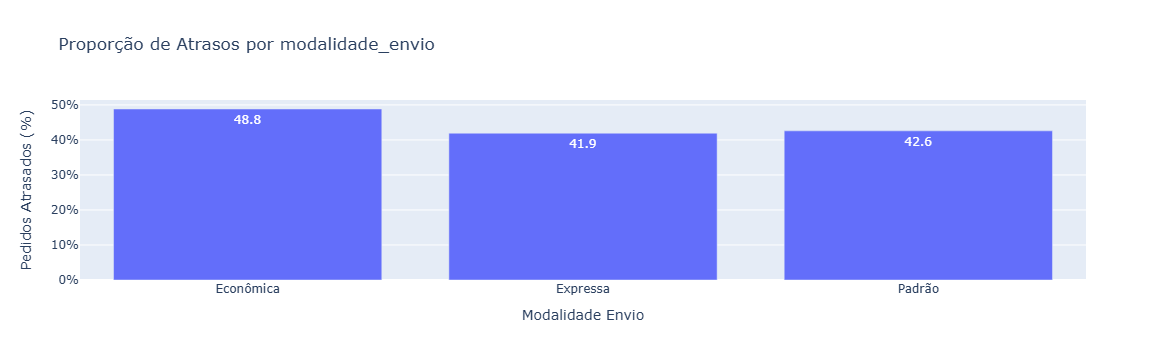

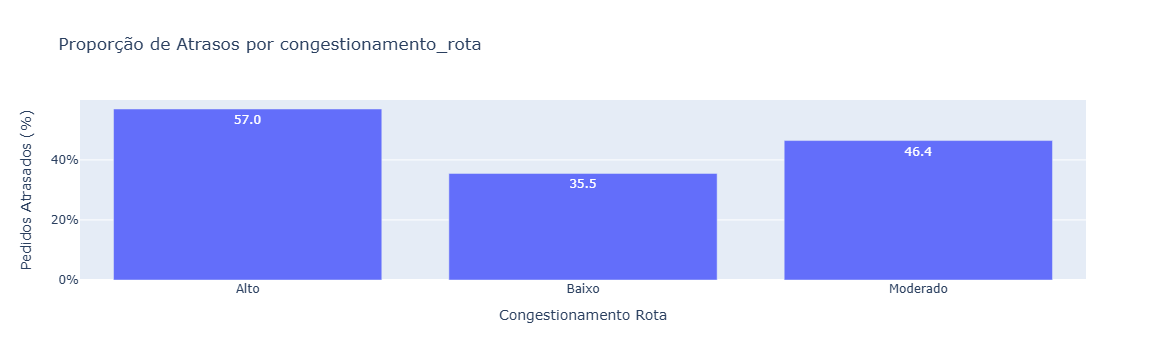

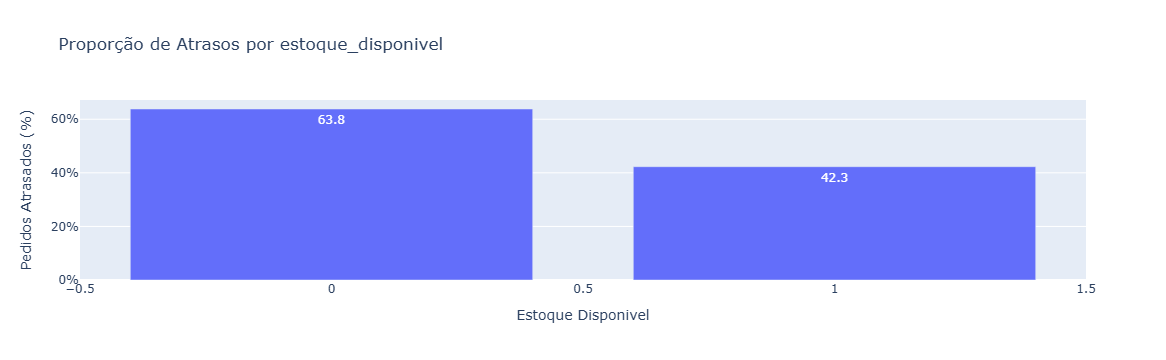

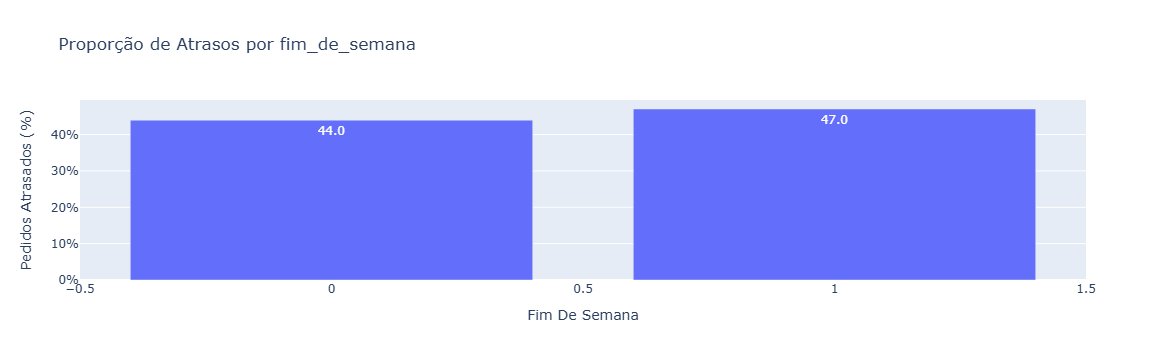

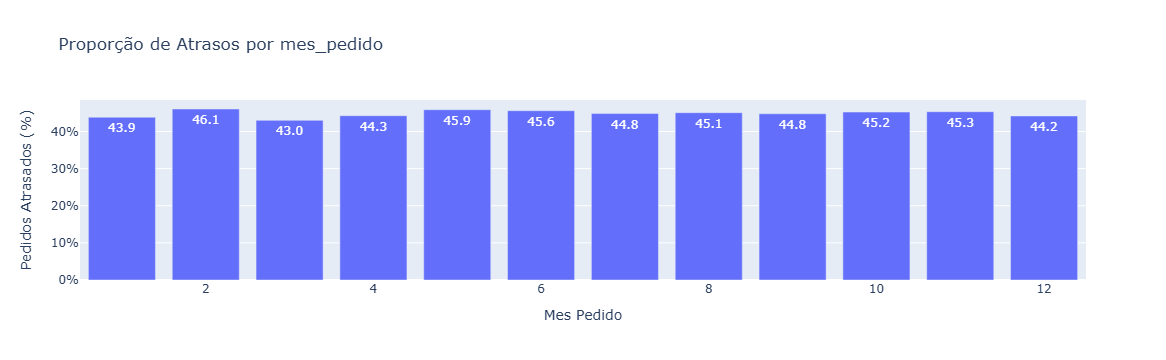

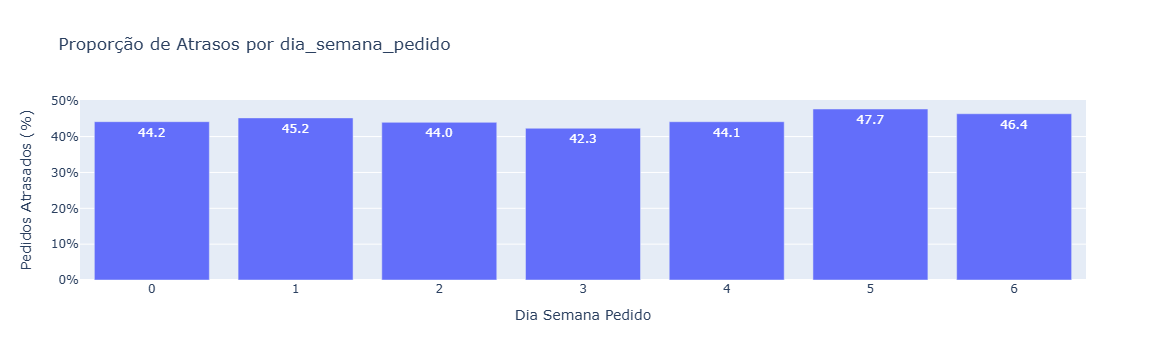

In [39]:
variaveis_categoricas = [
    'regiao_destino',
    'estado_destino',
    'categoria_produto',
    'transportadora',
    'modalidade_envio',
    'congestionamento_rota',
    'estoque_disponivel',
    'fim_de_semana',
    'mes_pedido',
    'dia_semana_pedido'
]

for coluna in variaveis_categoricas:
    df_proporcao = (
        df_train.groupby(coluna)['atrasou']
        .mean()
        .reset_index()
    )
    
    df_proporcao['atrasou'] = df_proporcao['atrasou'] * 100
    
    fig = px.bar(
        df_proporcao,
        x=coluna,
        y='atrasou',
        title=f'Proporção de Atrasos por {coluna}',
        labels={
            coluna: coluna.replace('_', ' ').title(),
            'atrasou': 'Pedidos Atrasados (%)'
        },
        text_auto='.1f'
    )
    fig.update_layout(
        yaxis_ticksuffix='%',
        yaxis_title='Pedidos Atrasados (%)',
        xaxis_title=coluna.replace('_', ' ').title()
    )

    fig.show()

Dentre os gráficos das variáveis categóricas, destaca-se:
- o alto congestionamento da rota e a falta de disponibilidade no estoque são grandes fatores de atrasos.
- a região Norte e o estado do Pará (junto com outros estados do Norte) concentram as maiores proporções de atrasos, quando comparados com as outras partes geográficas.
- a modalidade de envio Econômica possui percentual elevado em compração com as demais modalidades.
- entre as transportadoras, a BrasiLog registrou maior percentual.
- em relação às categorias de produto e às variáveis relacionadas ao período do pedido, foram observadas diferenças relativamente menores entre suas categorias, embora algumas variações também possam ser observadas.

### 3.3 Seleção das Variáveis Preditoras

In [40]:
colunas_remover = [
    'fim_de_semana',
    'regiao_destino'
]

X_train = X_train.drop(columns=colunas_remover)
X_test = X_test.drop(columns=colunas_remover)

Todas as variáveis foram escolhidas, a primeiro momento, exceto fim_de_semana e regiao_destino, pois ambas são reduntantes. Isso foi concluído visto que a informação de fim de semana já está contida em dia_semana_pedido, e a região já é determinada pelo estado.

### 3.4 Transformação e Preparação das Variáveis Selecionadas

In [41]:
colunas_categoricas.remove('regiao_destino')
colunas_categoricas

['estado_destino',
 'categoria_produto',
 'transportadora',
 'modalidade_envio',
 'congestionamento_rota',
 'mes_pedido',
 'dia_semana_pedido']

In [43]:
colunas_numericas

['distancia_km',
 'valor_pedido_brl',
 'carga_centro_distribuicao_pct',
 'chuva_prevista_mm',
 'lead_time_fornecedor_dias',
 'dias_prometidos']

In [44]:
preprocessor = make_column_transformer(
    (OneHotEncoder(handle_unknown='ignore'), colunas_categoricas),
    (MinMaxScaler(), colunas_numericas),
    remainder='passthrough',
    sparse_threshold=0
)

In [45]:
X_train_transformed = preprocessor.fit_transform(X_train)
X_test_transformed = preprocessor.transform(X_test)

In [49]:
preprocessor.get_feature_names_out()

array(['onehotencoder__estado_destino_AC',
       'onehotencoder__estado_destino_AL',
       'onehotencoder__estado_destino_AM',
       'onehotencoder__estado_destino_AP',
       'onehotencoder__estado_destino_BA',
       'onehotencoder__estado_destino_CE',
       'onehotencoder__estado_destino_DF',
       'onehotencoder__estado_destino_ES',
       'onehotencoder__estado_destino_GO',
       'onehotencoder__estado_destino_MA',
       'onehotencoder__estado_destino_MG',
       'onehotencoder__estado_destino_MS',
       'onehotencoder__estado_destino_MT',
       'onehotencoder__estado_destino_PA',
       'onehotencoder__estado_destino_PB',
       'onehotencoder__estado_destino_PE',
       'onehotencoder__estado_destino_PI',
       'onehotencoder__estado_destino_PR',
       'onehotencoder__estado_destino_RJ',
       'onehotencoder__estado_destino_RN',
       'onehotencoder__estado_destino_RO',
       'onehotencoder__estado_destino_RR',
       'onehotencoder__estado_destino_RS',
       'one

## 4. Modelagem Preditiva

### 4.1 Regressão Logística

### 4.2 K-Nearest Neighbors (KNN)

### 4.3 Random Forest

### 4.4 XGBoost

## 5. Avaliação dos Modelos

### 5.1 Métricas de Avaliação

### 5.2 Comparação dos Modelos

### 5.3 Matrizes de Confusão

### 5.4 Análise dos Resultados

### 5.5 Importância das Variáveis

## 6. Conclusões

### 6.1 Principais Resultados

### 6.2 Limitações do Estudo

### 6.3 Possíveis Melhorias